In [50]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression , Lasso ,Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.experimental import enable_hist_gradient_boosting  # Needed for HistGB
from sklearn.ensemble import (RandomForestRegressor,ExtraTreesRegressor,BaggingRegressor,
                              AdaBoostRegressor ,GradientBoostingRegressor,HistGradientBoostingRegressor
                              , VotingRegressor,StackingRegressor)
#import xgboost as xgb
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
#import lightgbm as lgb
from lightgbm import LGBMRegressor

In [51]:
df = pd.read_csv('House_Rent_Dataset.csv')
df.head()

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,5/18/2022,2,10000.0,1100.0,Ground out of 2,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2.0,Contact Owner
1,5/13/2022,2,20000.0,NaN,1 out of 3,Super Area,"Phool Bagan, Kankurgachi",Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Owner
2,5/16/2022,2,17000.0,1000.0,1 out of 3,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Owner
3,7/4/2022,2,10000.0,NaN,1 out of 2,Super Area,Dumdum Park,Kolkata,Unfurnished,Bachelors/Family,1.0,Contact Owner
4,5/9/2022,2,7500.0,850.0,1 out of 2,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1.0,Contact Owner


| اسم العمود            | الشرح                                                                                                            |
| --------------------- | ---------------------------------------------------------------------------------------------------------------- |
| **Posted On**         | تاريخ نشر إعلان العقار للإيجار.                                                                                  |
| **BHK**               | عدد غرف النوم والصالة والمطبخ في العقار.                                                                         |
| **Rent**              | قيمة الإيجار الشهري للعقار.                                                                                      |
| **Size**              | مساحة العقار، وغالبًا تُقاس بالقدم المربع (Square Feet).                                                         |
| **Floor**             | رقم الطابق الذي يقع فيه العقار وإجمالي عدد طوابق المبنى.                                                         |
| **Area Type**         | نوع المساحة المستخدمة في القياس، مثل المساحة الكلية (Super Area) أو المساحة الداخلية الصافية (Carpet Area).      |
| **Area Locality**     | اسم المنطقة أو الحي الذي يقع فيه العقار.                                                                         |
| **City**              | المدينة التي يوجد بها العقار.                                                                                    |
| **Furnishing Status** | حالة تأثيث العقار: مفروش (Furnished)، نصف مفروش (Semi-Furnished)، أو غير مفروش (Unfurnished).                    |
| **Tenant Preferred**  | نوع المستأجر الذي يفضله المالك، مثل الأفراد (Bachelors) أو العائلات (Family).                                    |
| **Bathroom**          | عدد الحمامات الموجودة في العقار.                                                                                 |
| **Point of Contact**  | الشخص المسؤول عن التواصل بخصوص العقار، مثل المالك (Owner) أو الوسيط العقاري (Agent) أو المطور العقاري (Builder). |

In [52]:
df.shape

(4746, 12)

In [53]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4746 entries, 0 to 4745
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Posted On          4746 non-null   str    
 1   BHK                4746 non-null   int64  
 2   Rent               4741 non-null   float64
 3   Size               4738 non-null   float64
 4   Floor              4746 non-null   str    
 5   Area Type          4739 non-null   str    
 6   Area Locality      4746 non-null   str    
 7   City               4746 non-null   str    
 8   Furnishing Status  4746 non-null   str    
 9   Tenant Preferred   4746 non-null   str    
 10  Bathroom           4742 non-null   float64
 11  Point of Contact   4746 non-null   str    
dtypes: float64(3), int64(1), str(8)
memory usage: 445.1 KB


In [54]:
df.describe()

,BHK,Rent,Size,Bathroom
count,4746.000000,4.741000e+03,4738.000000,4742.000000
mean,2.083860,3.502340e+04,967.936049,1.965837
std,0.832256,7.814214e+04,634.562635,0.884904
min,1.000000,1.200000e+03,10.000000,1.000000
25%,2.000000,1.000000e+04,550.000000,1.000000
50%,2.000000,1.600000e+04,850.000000,2.000000
75%,3.000000,3.300000e+04,1200.000000,2.000000
max,6.000000,3.500000e+06,8000.000000,10.000000


In [55]:
df.describe(include='object')

C:\Users\PC\AppData\Local\Temp\ipykernel_25072\87514550.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='object')


,Posted On,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Point of Contact
count,4746,4746,4739,4746,4746,4746,4746,4746
unique,81,480,3,2235,6,3,3,3
top,7/6/2022,1 out of 2,Super Area,Bandra West,Mumbai,Semi-Furnished,Bachelors/Family,Contact Owner
freq,311,379,2442,37,972,2251,3444,3216


In [56]:
df.isnull().sum().sort_values(ascending=False)

Size                 8
Area Type            7
Rent                 5
Bathroom             4
Posted On            0
BHK                  0
Area Locality        0
Floor                0
City                 0
Furnishing Status    0
Tenant Preferred     0
Point of Contact     0
dtype: int64

In [57]:
df.dropna(inplace=True)

In [58]:
df.duplicated().sum()

np.int64(0)

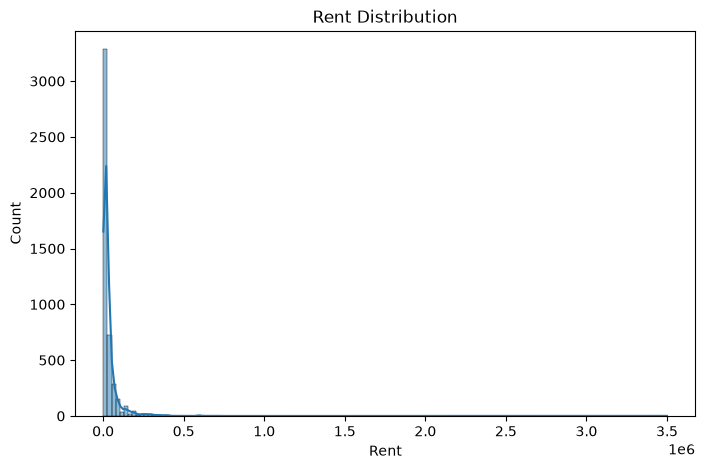

In [59]:
plt.figure(figsize=(8,5))
sns.histplot(df['Rent'], kde=True)
plt.title('Rent Distribution')
plt.show()

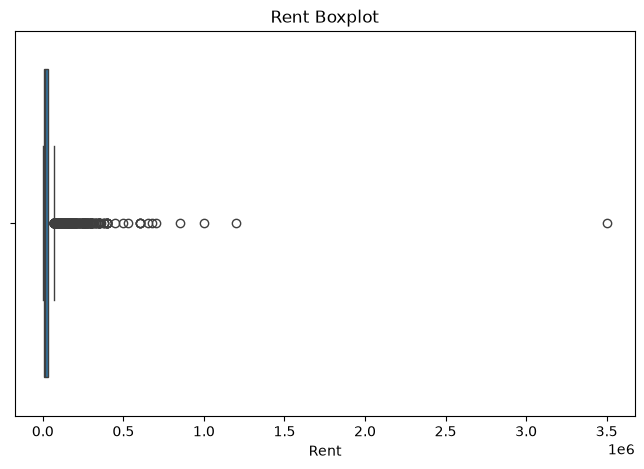

In [60]:
plt.figure(figsize=(8,5))
sns.boxplot(x=df['Rent'])
plt.title('Rent Boxplot')
plt.show()

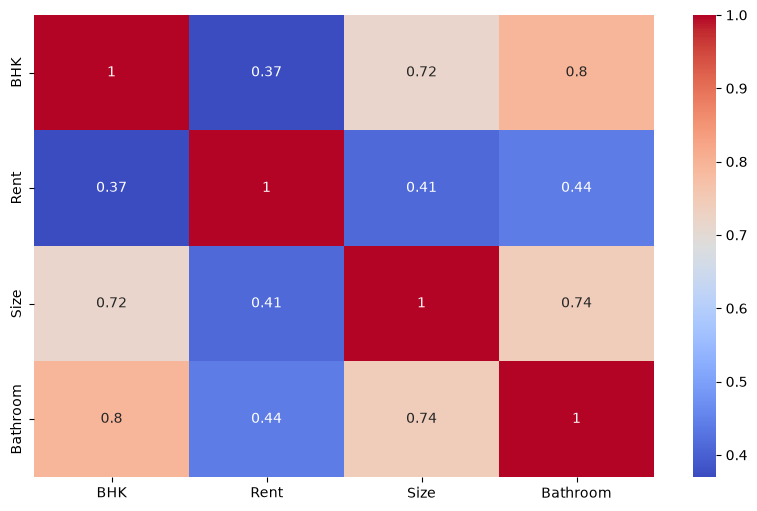

In [61]:
plt.figure(figsize=(10,6))
sns.heatmap(df.select_dtypes(include=np.number).corr(),
            annot=True, cmap='coolwarm')
plt.show()

In [62]:
X = df.drop(columns=['Rent'])
y = df['Rent']

In [63]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [64]:
num_cols = X_train.select_dtypes(include=np.number).columns

cat_cols = X_train.select_dtypes(include='object').columns


C:\Users\PC\AppData\Local\Temp\ipykernel_25072\2969684399.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X_train.select_dtypes(include='object').columns


In [65]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

X_train_encoded = encoder.fit_transform(X_train[cat_cols])
X_test_encoded = encoder.transform(X_test[cat_cols])

In [66]:
encoded_cols = encoder.get_feature_names_out(cat_cols)

X_train_encoded = pd.DataFrame(
    X_train_encoded,
    columns=encoded_cols,
    index=X_train.index
)

X_test_encoded = pd.DataFrame(
    X_test_encoded,
    columns=encoded_cols,
    index=X_test.index
)

In [67]:
X_train_final = pd.concat(
    [X_train[num_cols], X_train_encoded], axis=1
)

X_test_final = pd.concat(
    [X_test[num_cols], X_test_encoded], axis=1
)

In [68]:
import re

def clean_columns(columns):
    new_cols = []
    used = set()

    for col in columns:
        name = re.sub(r'[^A-Za-z0-9_]', '_', str(col))

        original_name = name
        counter = 1

        while name in used:
            name = f"{original_name}_{counter}"
            counter += 1

        used.add(name)
        new_cols.append(name)

    return new_cols


X_train_final.columns = clean_columns(X_train_final.columns)

X_test_final.columns = X_train_final.columns.copy()

In [69]:
X_train_encoded.head()

,Posted On_4/13/2022,Posted On_4/23/2022,Posted On_4/24/2022,Posted On_4/25/2022,Posted On_4/26/2022,Posted On_4/27/2022,Posted On_4/28/2022,Posted On_4/29/2022,Posted On_4/30/2022,Posted On_5/1/2022,...,City_Mumbai,Furnishing Status_Furnished,Furnishing Status_Semi-Furnished,Furnishing Status_Unfurnished,Tenant Preferred_Bachelors,Tenant Preferred_Bachelors/Family,Tenant Preferred_Family,Point of Contact_Contact Agent,Point of Contact_Contact Builder,Point of Contact_Contact Owner
1437,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
3132,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
1686,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
274,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
957,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0


In [70]:
models ={
    "Linear Regression":LinearRegression(),
    "Lasso":Lasso(),
    "Ridge":Ridge(),
    "KNN":KNeighborsRegressor(n_neighbors=5,metric='minkowski',p=1), #  minkowski , euclidean , manhattan
    "SVM":SVR(kernel='linear', C=100, gamma=1), # kernel='rbf' / kernel='poly', degree=4 / kernel='sigmoid
    "Decision Tree":DecisionTreeRegressor(criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "Random Forest":RandomForestRegressor(n_estimators=50,criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion='squared_error',max_depth=10),n_estimators=50, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0),
    "CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

In [71]:
# Metrics function
def regression_metrics(model, X, y_actual):
    y_pred = model.predict(X)
    MAE = mean_absolute_error(y_actual, y_pred)
    MSE = mean_squared_error(y_actual, y_pred)
    RMSE = np.sqrt(MSE)
    R2 = r2_score(y_actual, y_pred)
    return MAE, MSE, RMSE, R2

  0%|          | 0/15 [00:00<?, ?it/s]

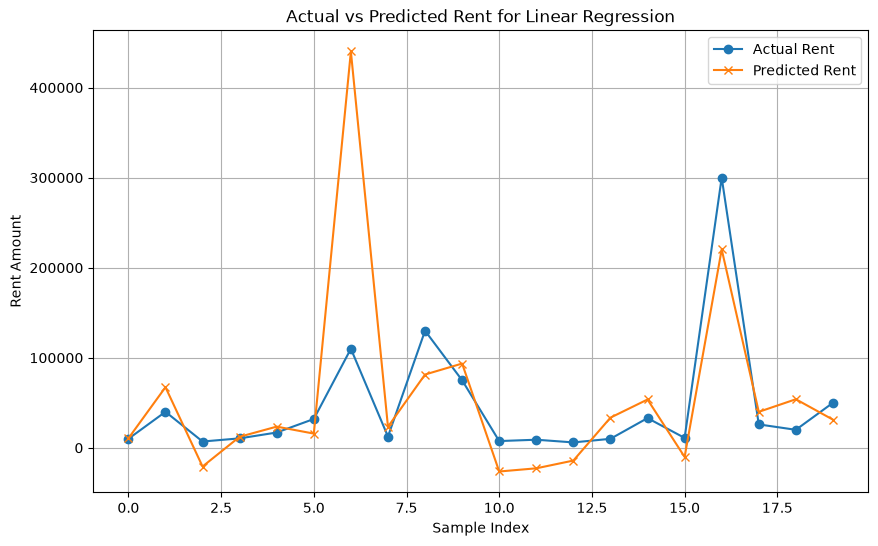

  7%|▋         | 1/15 [00:04<01:07,  4.79s/it]c:\Users\PC\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:840: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.641161e+11, tolerance: 2.581e+09
  model = cd_fast.enet_coordinate_descent(


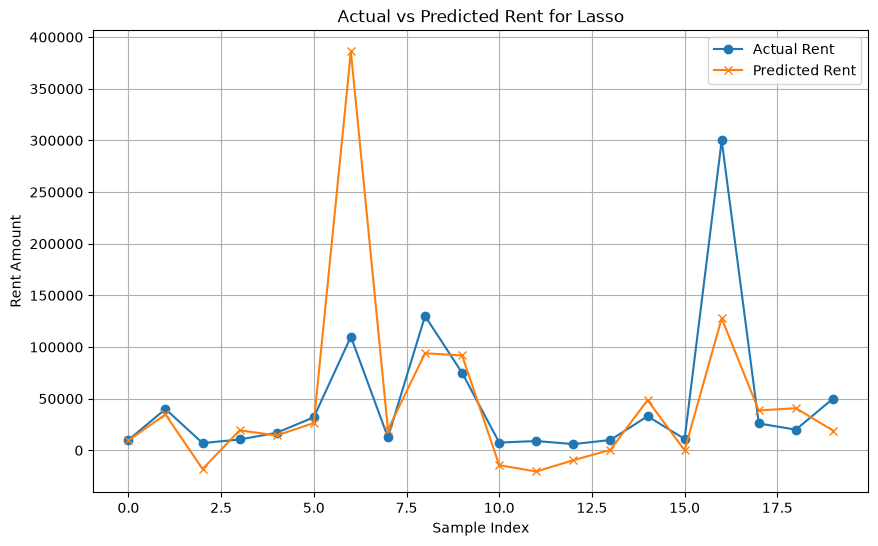

 13%|█▎        | 2/15 [00:12<01:22,  6.32s/it]

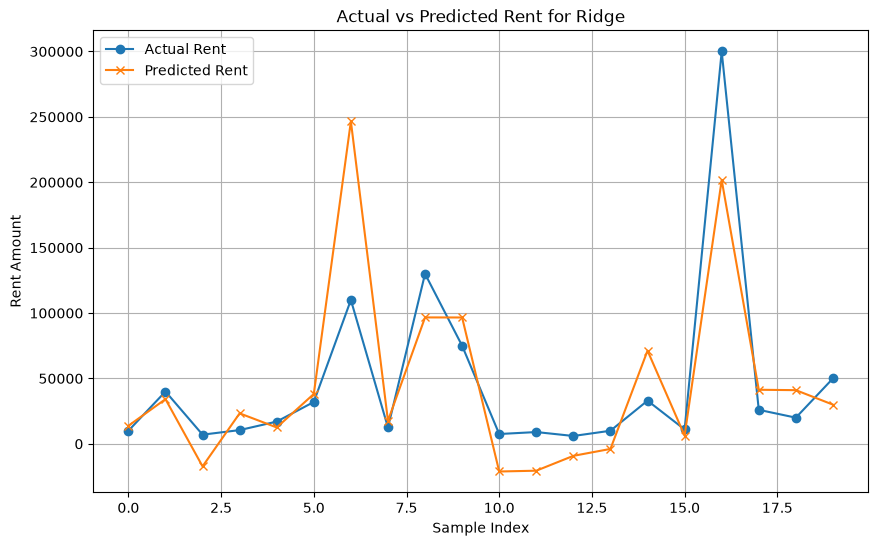

 20%|██        | 3/15 [00:13<00:48,  4.02s/it]

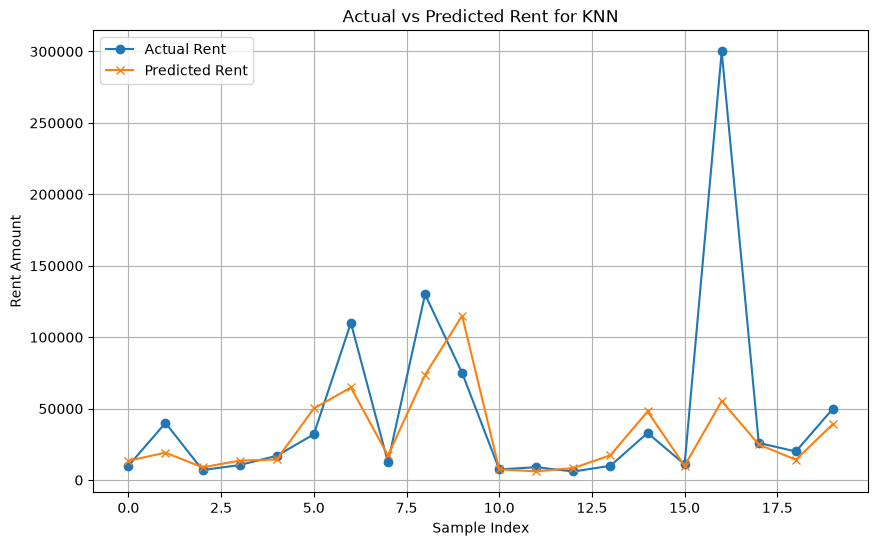

 27%|██▋       | 4/15 [00:39<02:19, 12.72s/it]

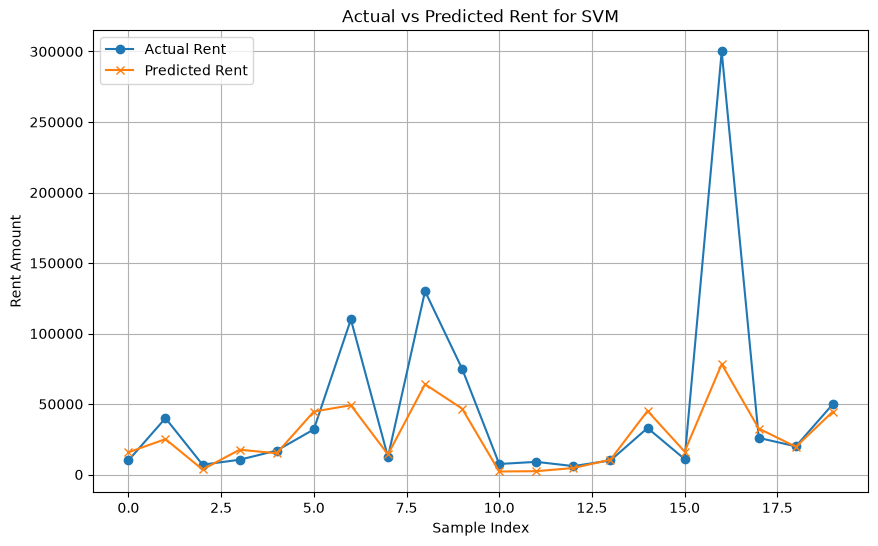

 33%|███▎      | 5/15 [06:56<23:59, 143.95s/it]

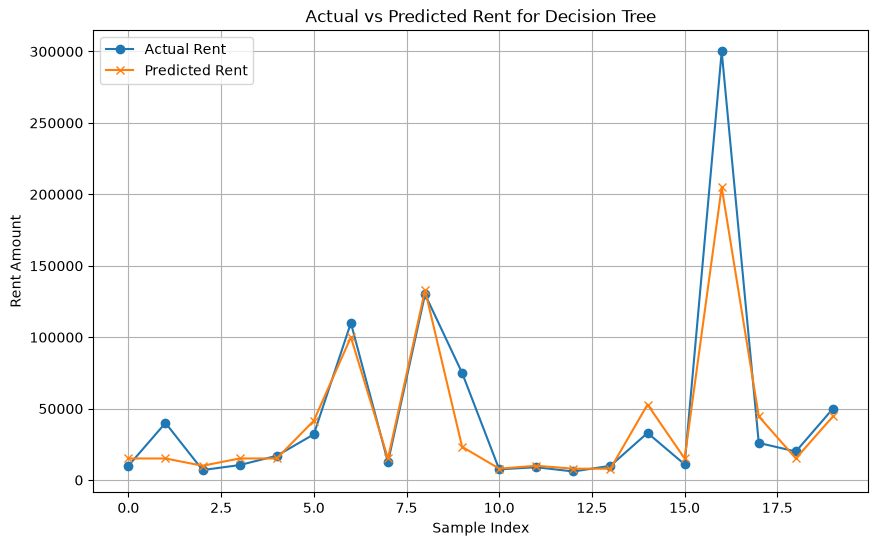

 40%|████      | 6/15 [06:57<14:19, 95.52s/it] 

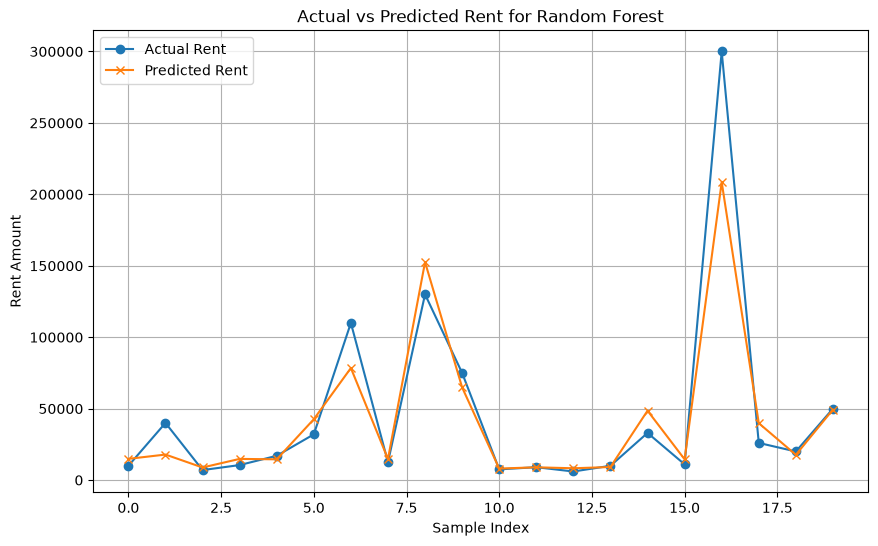

 47%|████▋     | 7/15 [07:11<09:11, 68.96s/it]

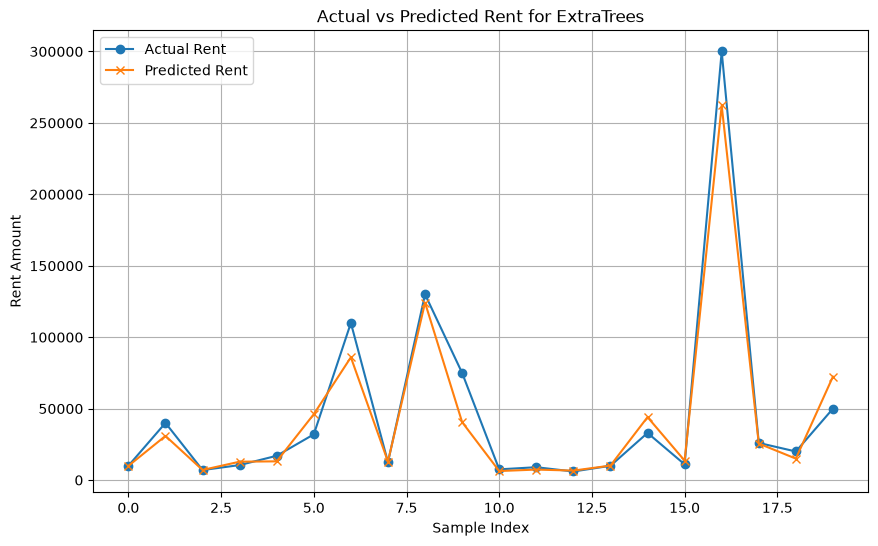

 53%|█████▎    | 8/15 [08:34<08:33, 73.35s/it]

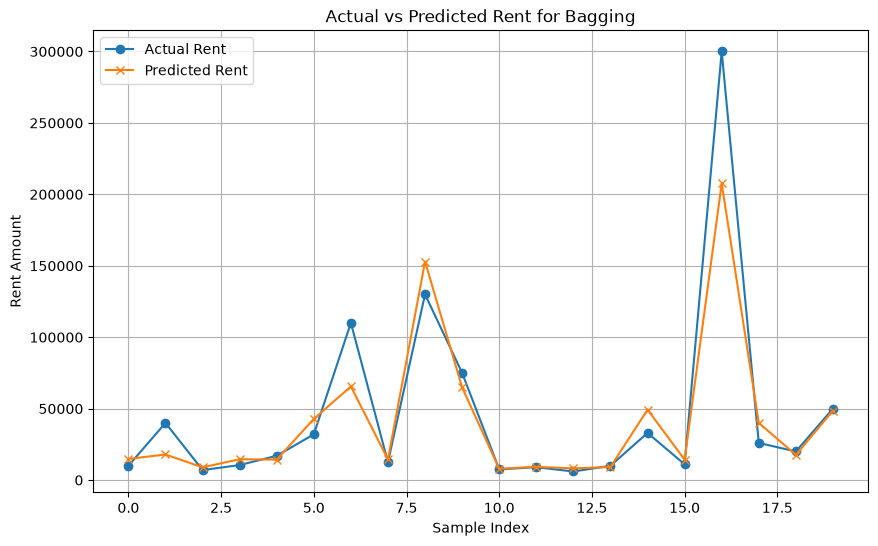

 60%|██████    | 9/15 [08:54<05:40, 56.70s/it]

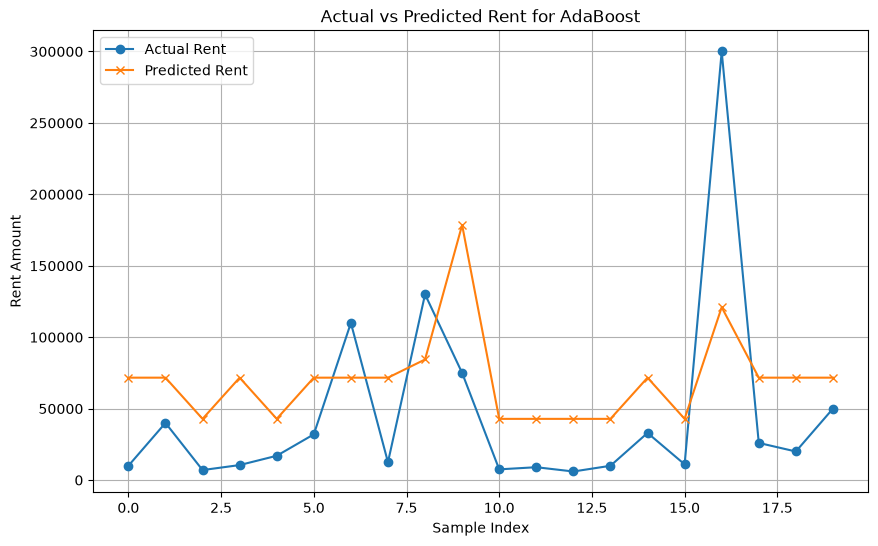

 67%|██████▋   | 10/15 [09:06<03:33, 42.70s/it]

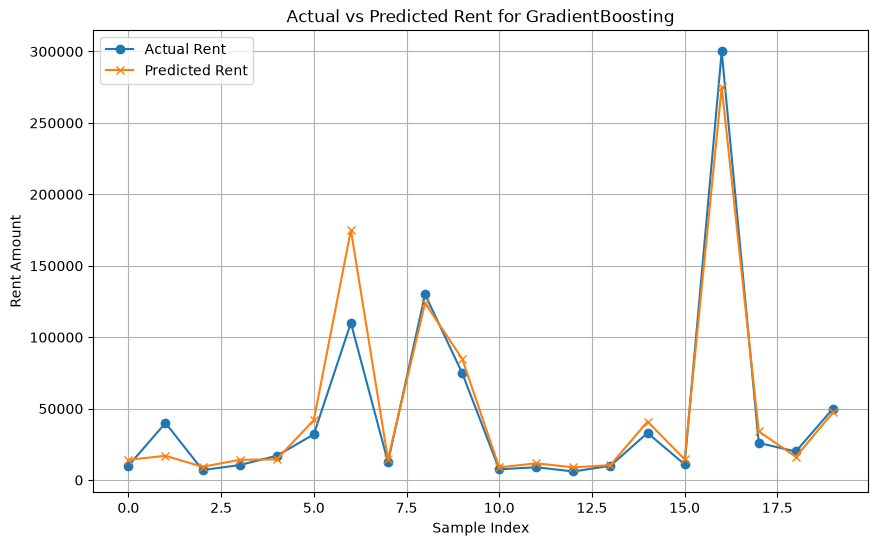

 73%|███████▎  | 11/15 [09:24<02:21, 35.26s/it]

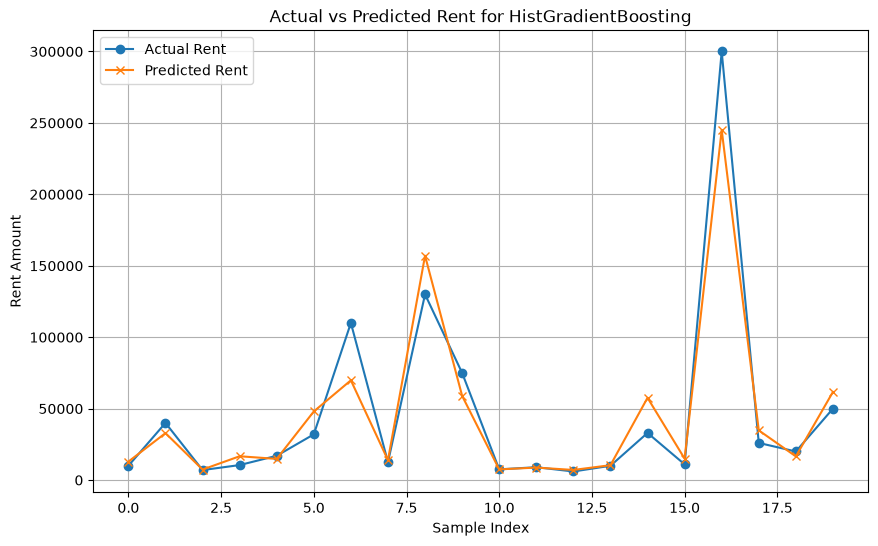

 80%|████████  | 12/15 [09:45<01:32, 30.85s/it]

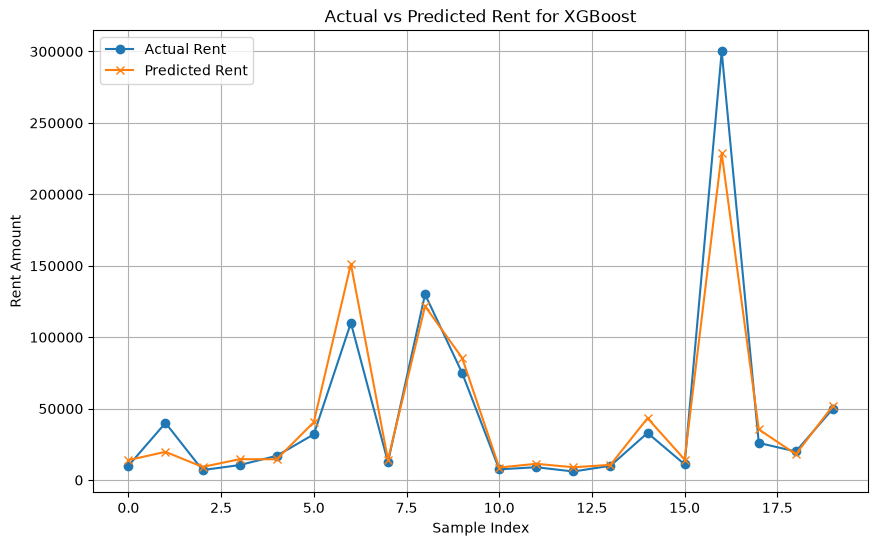

 87%|████████▋ | 13/15 [09:50<00:46, 23.12s/it]

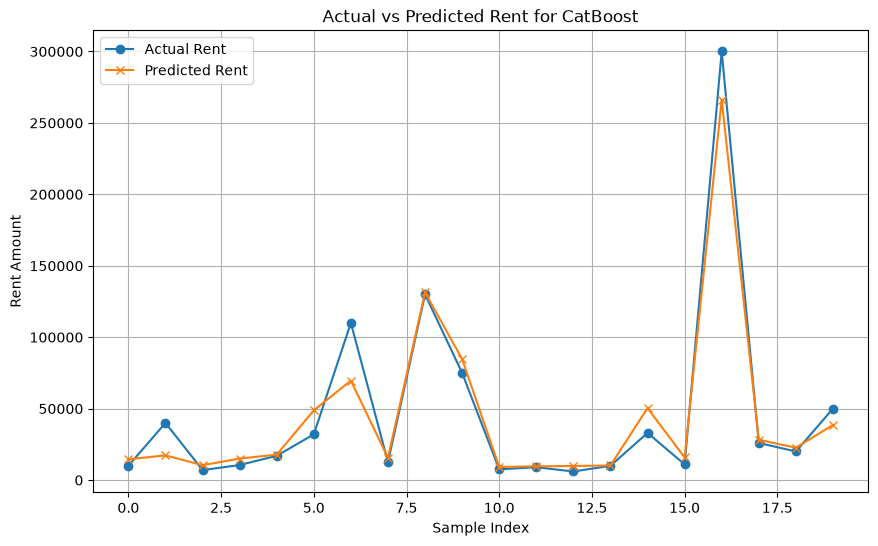

 93%|█████████▎| 14/15 [09:54<00:17, 17.24s/it]

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000988 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 459
[LightGBM] [Info] Number of data points in the train set: 3780, number of used features: 105
[LightGBM] [Info] Start training from score 36157.454233


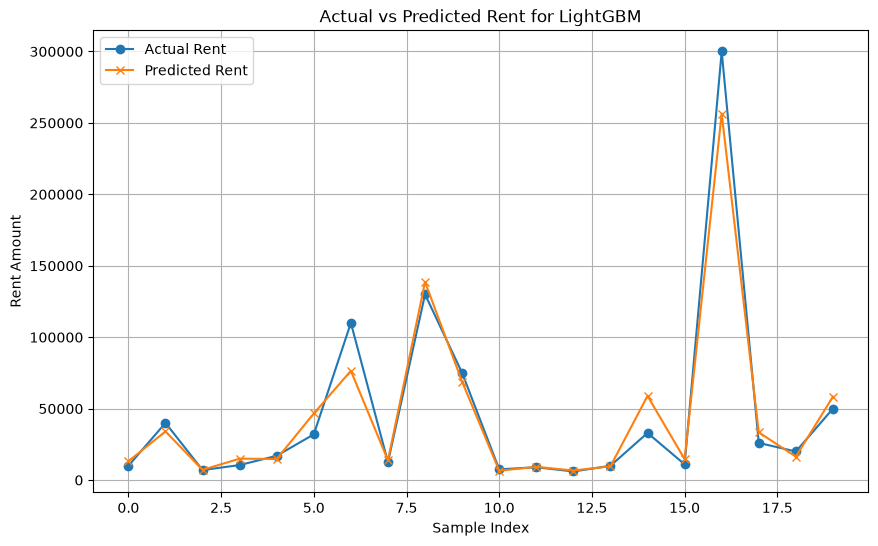

100%|██████████| 15/15 [09:55<00:00, 39.70s/it]


In [72]:

errors = {}

for model_name, model in tqdm(models.items()):

    model.fit(X_train_final, y_train)

    MAE_Train, MSE_Train, RMSE_Train, R_Train = regression_metrics(
        model, X_train_final, y_train
    )

    MAE_Test, MSE_Test, RMSE_Test, R_Test = regression_metrics(
        model, X_test_final, y_test
    )

    errors[model_name] = {
        "MAE Train": MAE_Train,
        "MAE Test": MAE_Test,
        "MSE Train": MSE_Train,
        "MSE Test": MSE_Test,
        "RMSE Train": RMSE_Train,
        "RMSE Test": RMSE_Test,
        "R2 Train": R_Train,
        "R2 Test": R_Test
    }

    # Plotting Actual vs Predicted for first 20 test samples
    y_test_plot = y_test.iloc[:20]
    y_pred_plot = model.predict(X_test_final.iloc[:20])

    plt.figure(figsize=(10, 6))
    plt.plot(range(len(y_test_plot)), y_test_plot,
             label='Actual Rent', marker='o')

    plt.plot(range(len(y_pred_plot)), y_pred_plot,
             label='Predicted Rent', marker='x')

    plt.xlabel('Sample Index')
    plt.ylabel('Rent Amount')
    plt.title('Actual vs Predicted Rent for ' + model_name)
    plt.legend()
    plt.grid()
    plt.show()


In [73]:
results_df = pd.DataFrame(errors).T
display(results_df)

,MAE Train,MAE Test,MSE Train,MSE Test,RMSE Train,RMSE Test,R2 Train,R2 Test
Linear Regression,11675.270704,31696.451967,2.178729e+09,5.242282e+09,46676.854397,72403.602012,0.680877,-0.595589
Lasso,12507.705501,27444.820734,2.190424e+09,4.818896e+09,46801.963638,69418.268815,0.679164,-0.466724
Ridge,15331.855845,23305.035042,2.557409e+09,2.859496e+09,50570.827909,53474.255763,0.625411,0.129657
KNN,15147.051111,15591.502960,3.609218e+09,2.734152e+09,60076.765401,52289.120877,0.471350,0.167808
SVM,17220.581555,13357.776979,5.603319e+09,2.354073e+09,74855.321943,48518.788524,0.179270,0.283493
Decision Tree,7717.389388,10976.621481,1.990047e+08,7.379143e+08,14106.901465,27164.578351,0.970851,0.775402
Random Forest,8460.820402,9852.963535,8.146901e+08,9.537156e+08,28542.776089,30882.286568,0.880671,0.709718
ExtraTrees,1.222222,9401.826004,5.640741e+02,1.149915e+09,23.750244,33910.395912,1.000000,0.650001
Bagging,8631.695723,9962.443433,8.832017e+08,8.909332e+08,29718.708828,29848.504350,0.870636,0.728827
AdaBoost,42326.690529,41806.098950,2.500706e+09,2.748691e+09,50007.059787,52427.958109,0.633716,0.163383
